# Laptop Data Analysis

### Dataset Selection

I selected the "LaptopData" dataset from kaggle:

[https://www.kaggle.com/datasets/ehtishamsadiq/uncleaned-laptop-price-dataset](url)

I chose this datasset to analyse the hardware used by different companies and to find the most widely used hardware at the time the data was collected.

The data in this dataset seems to have been collected between 2016 and 2020, I know this as I have found a graphics card in the dataset that was released in 2016 and the lack of 20 series cards (which were released in 2020). While the card released in 2016 means this data set is definitely collected after that the lack of 20 series cards is an assumption though I believe a sound one, usually when new NVIDIA card series are released it's a about a month before they are released in laptops.

In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [55]:
data = pd.read_csv("data.csv")
data.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Gpu,OpSys,Weight,Price,GPU Brand
0,Apple,Ultrabook,13.3,2560x1600,Intel Core i5 2.3GHz,8GB,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832,Intel
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,Intel HD Graphics 6000,macOS,1.34kg,47895.5232,Intel
2,HP,Notebook,15.6,1920x1080,Intel Core i5 7200U 2.5GHz,8GB,Intel HD Graphics 620,No OS,1.86kg,30636.0000,Intel
3,Apple,Ultrabook,15.4,2880x1800,Intel Core i7 2.7GHz,16GB,AMD Radeon Pro 455,macOS,1.83kg,135195.3360,AMD
4,Apple,Ultrabook,13.3,2560x1600,Intel Core i5 3.1GHz,8GB,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080,Intel


### What is the most widely used GPU brand for each company?

Text(0, 0.5, 'Laptop releases')

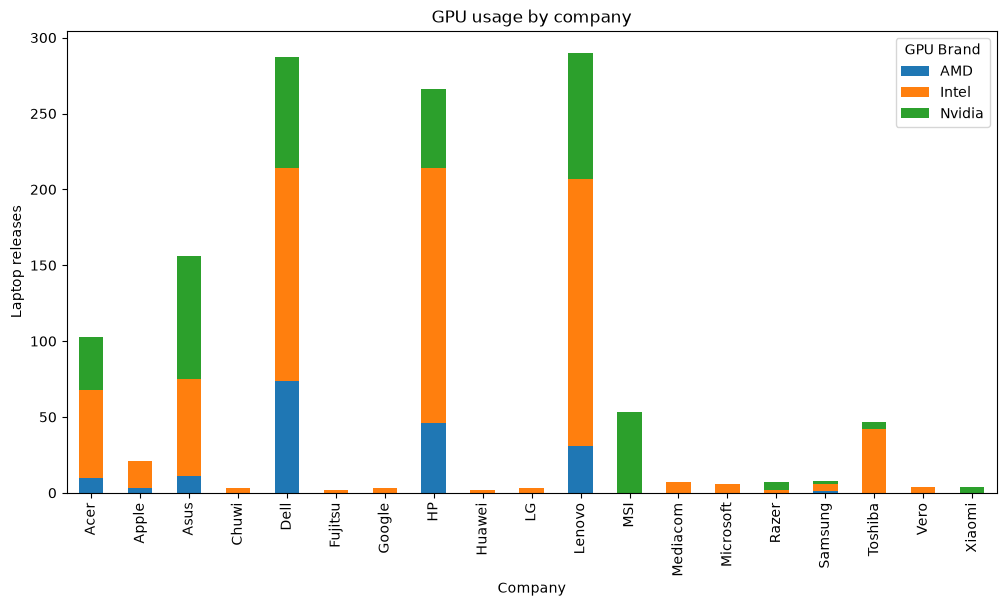

In [39]:
gpu_counts = data.pivot_table(
    index="Company",
    columns="GPU Brand",
    aggfunc="size",
    fill_value=0
)
gpu_counts.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("GPU usage by company")
plt.ylabel("Laptop releases")

As this figure shows the most widely used GPU brand is intel, however if we look closer into this we can see that the intel GPUs are actually integrated graphics (meaning no GPU just graphics powered by the CPU), so if we are looking for GPUs specifically we should disregard the intel data for this question. Though as a side note this does show which companies are making laptops for users who are likely to need more graphical processing power such as gamers and graphic designers (MSI & Xiaomi).

Text(0, 0.5, 'Laptop releases')

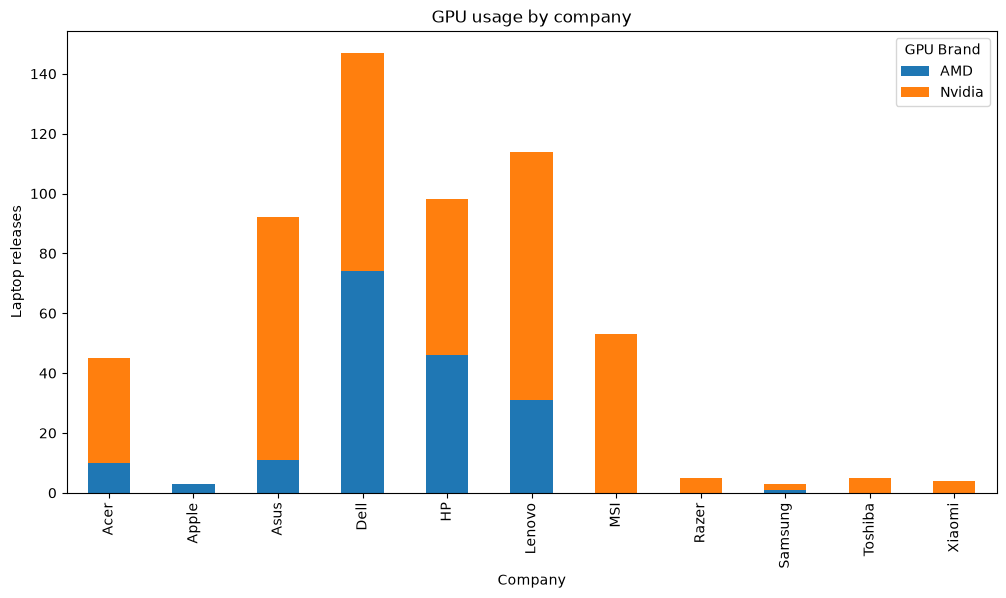

In [40]:
gpu_counts = gpu_counts.drop("Intel",axis=1)
gpu_counts = gpu_counts.loc[(gpu_counts != 0).any(axis=1)]
gpu_counts.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("GPU usage by company")
plt.ylabel("Laptop releases")

Now we've cleared all of the integrated graphics out and removed the companies only using integrated graphics we have a clearer picture of each company's use of AMD and Nvidia with Nvidia coming out on top suggesting it's a better buisness choice, this could come from any combination of factors from price to quality. Though it is interesting to note that companies that focus on gaming (e.g. MSI & Razer) tend to use Nvidia whereas companies that focus on laptops for work (e.g. Dell, HP and Lenovo) have a better distribution of both companies GPUs, likely as the AMD GPUs tend to be cheaper.

### Which companies include the most RAM?

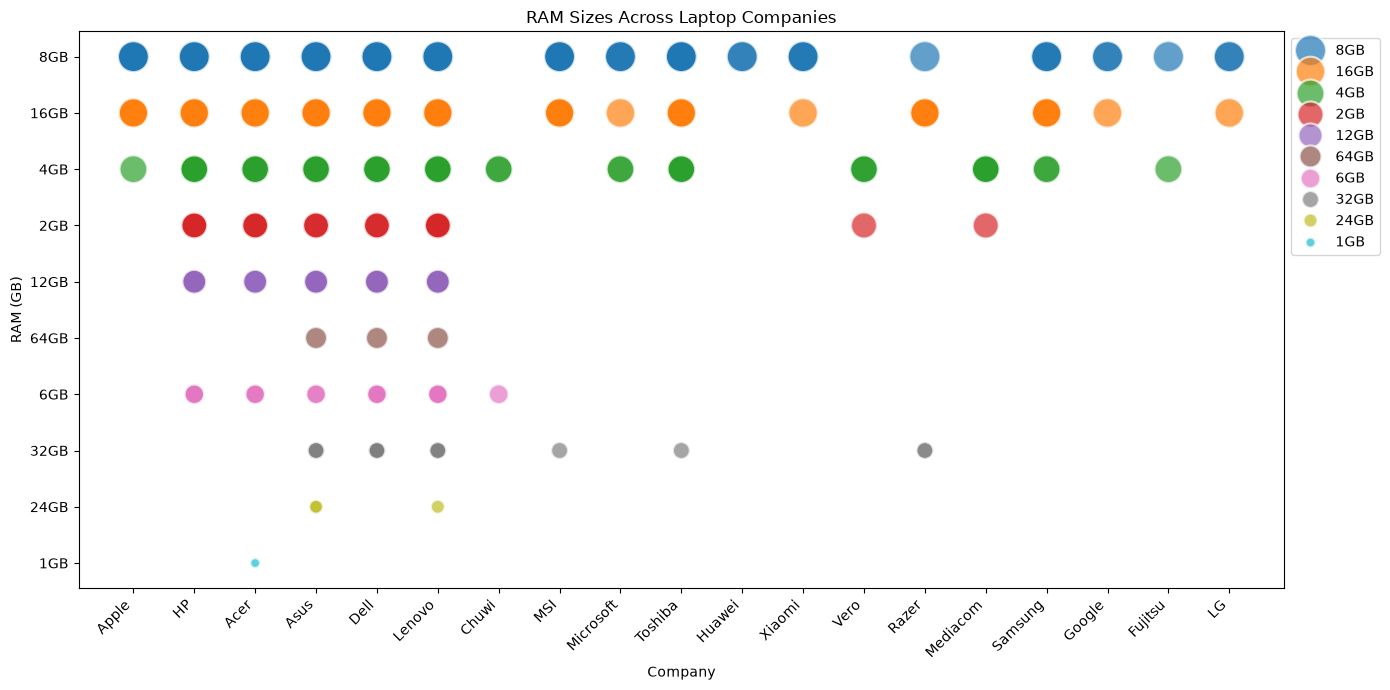

In [45]:
memory_counts = data.groupby(["Company", "Ram"]).size().unstack(fill_value=0)

memory_counts = memory_counts.reindex(
    sorted(memory_counts.columns, key=lambda x: float(x.replace("GB", ""))),
    axis=1
)
plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=data,
    x="Company",
    y="Ram",
    size="Ram",
    hue="Ram",
    sizes=(50, 500),
    alpha=0.7
)

plt.title("RAM Sizes Across Laptop Companies")
plt.xlabel("Company")
plt.ylabel("RAM (GB)")
plt.xticks(rotation=45, ha="right")
plt.legend(bbox_to_anchor=(1.0, 1), loc="upper left")
plt.tight_layout()

This figure shows us that most companies in this dataset released the most laptops with 8GB of RAM (with 16GB not far behind) though ASUS, Dell and Lenovo are the only companies to release laptops with 64GB of RAM which is interesting given the previous reasoning, where I reasoned that as these companies focused on laptops for work they likely used AMD GPUs as they are generally cheaper. This the data from this figure combined with the information from the prior would seem to suggest that these 3 companies have a more diverse range of products, including potentially laptops specialised for roles that may require more RAM. I come to this conclusion over them making high end gaming laptops as we can see that the companies we know to be focused towards gaming have only gone up to 32GB at their peak suggesting that high end gaming does not require 64GB of RAM or it would not be profitable to sell.

### What companies use what screen resolutions?

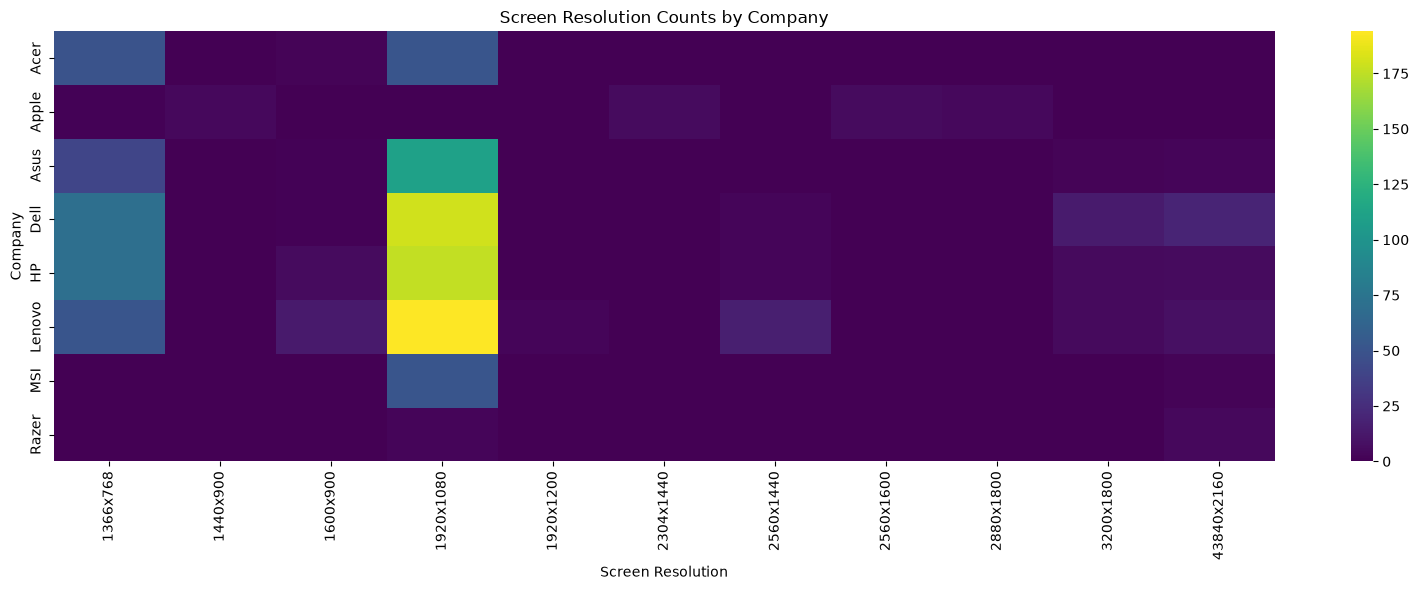

In [61]:
res_counts = data.pivot_table(
    index="Company",
    columns="ScreenResolution",
    aggfunc="size",
    fill_value=0
)
companies = ["Acer","Asus", "Dell", "Lenovo", "MSI", "Razer", "HP","Apple"]
filtered_counts = res_counts.loc[
    res_counts.index.isin(companies)
]
filtered_counts = filtered_counts.loc[:, (filtered_counts != 0).any(axis=0)]
plt.figure(figsize=(16, 6))
sns.heatmap(filtered_counts, cmap="viridis")

plt.title("Screen Resolution Counts by Company")
plt.xlabel("Screen Resolution")
plt.ylabel("Company")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

For this figure I have limited the companies we're looking at to the ones that were providing us with the most relevent information from our previous analysis and the most laptop releases, the other companies either had a low number of laptops for sale, tended to the same patterns or realeased only a few low end laptops. Here we can see a tight grouping with most of the laptops having 1080p screens with a few companies offering 4k as well. Interestingly we can see the companiesfocused on work laptops(Lenovo,Dell,HP) have a good range of resolutions mostly skewing towards the loer resolutions but there being distinct numbers in the high res too which seems to suggest that altough their focus is on work products they may have other product lines aswell. MSI and Razer are very interesting in this figure as they are showing opposite tendencies while having the same market (gamers) MSI appears to be focusing on performance and by extension battery life wheras Razer though they have fewer releases are mostly 4k which can be intensive for a desktop let alone a laptop.

## Summary

### Key findings

The discription of the most common laptop from this dataset (from which we can infer to be the most reliably profitable of this time period) was a 1080p, 8GB of RAM with integrated graphics. That said, the medium to high end of laptops were made with Nvidia GPUs. I found that Dell,HP,Lenovo and ASUS had the most laptop releases centering around laptops for work (e.g. lower resolution, integrated graphics and 8GB RAM). Though Dell, Lenovo and ASUS seem to also do some very high end laptops (e.g. 64GB RAM, 4k resolution with Nvidia GPUs).

### Trends

- Most Laptops with GPUs use Nvidia though correlation suggests that work laptops may use AMD.
- The Majority of laptops were mid to low end
- most laptops standardise to 1080p screens
- most laptops had 8GB of RAM

### Unexpected results

The two companies that made gaming laptops split off into two different categories of resolutions while having similar hardware suggesting contrasting strategies potentially the smaller company 'Razer' trying to find a niche.

#### Other notes

This dataset ended up being very messy and took a while to clean as it was scraped from a site with inconsistent listings. Also it only contained the name of the CPU rather than it's specifications making it impossible to compare by CPU without importing another dataset of specifications e.g. you cant compare clock speed if you dont know how many cores it has.